<center><h1>Zhu_Lingfei_HW5</h1></center>
<br>
<br>

Name: Zhu Lingfei
<br>
Github Username: youth0505
<br>
USC ID: 8599420339

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

from xgboost import XGBRegressor

RANDOM_STATE = 552
DATA_DIR = Path("../Data")
DIAGNOSIS_PATH = DATA_DIR / "diagnosis.data"
COMMUNITIES_PATH = DATA_DIR / "communities.data"
COMMUNITIES_NAMES_PATH = DATA_DIR / "communities.names"

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
diagnosis_columns = [
    "temperature", "nausea", "lumbar_pain", "urine_pushing",
    "micturition_pains", "burning_urethra",
    "bladder_inflammation", "nephritis"
]

acute = pd.read_csv(
    DIAGNOSIS_PATH,
    sep="\t",
    header=None,
    names=diagnosis_columns,
    encoding="utf-16"
)

acute["temperature"] = (
    acute["temperature"]
    .str.replace(",", ".", regex=False)
    .astype(float)
)

for col in diagnosis_columns[1:]:
    acute[col] = acute[col].map({"yes": 1, "no": 0}).astype("int64")

X_acute = acute.iloc[:, :6].astype(float)
y_acute = acute[["bladder_inflammation", "nephritis"]].astype("int64")

display(acute.head())
print(X_acute.dtypes)
print(y_acute.dtypes)

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


temperature          float64
nausea               float64
lumbar_pain          float64
urine_pushing        float64
micturition_pains    float64
burning_urethra      float64
dtype: object
bladder_inflammation    int64
nephritis               int64
dtype: object


### (b) Build a decision tree

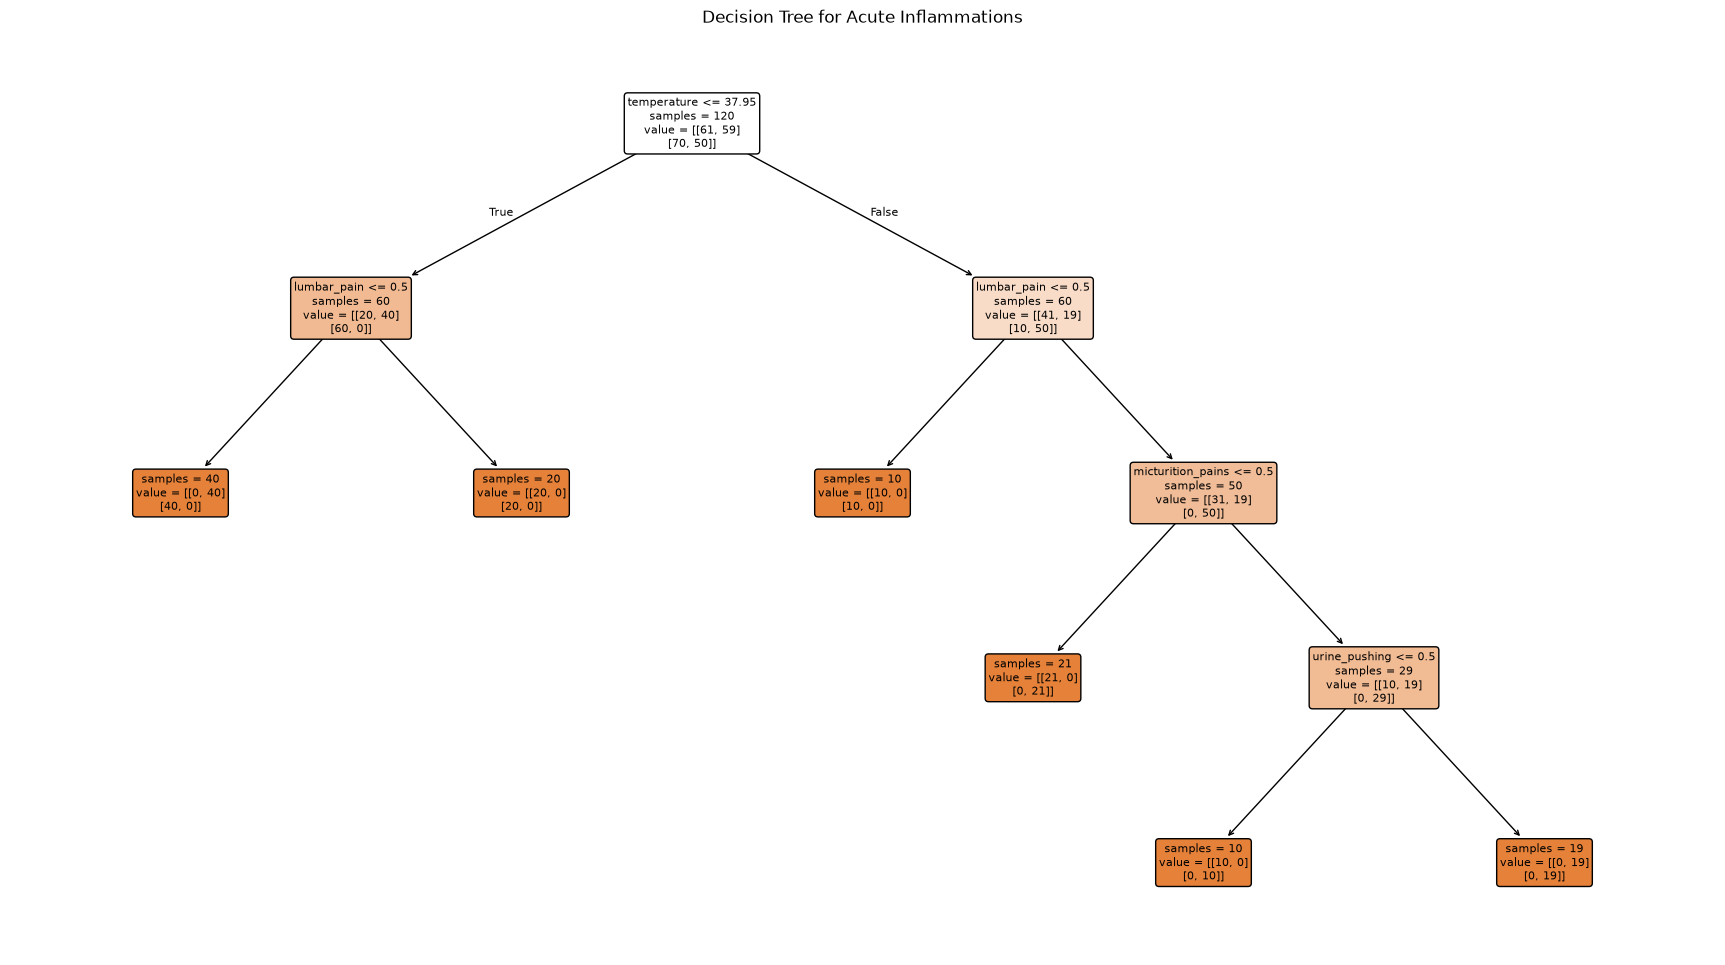

In [3]:
tree_full = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_full.fit(X_acute, y_acute)

plt.figure(figsize=(22, 12))
plot_tree(
    tree_full,
    feature_names=X_acute.columns,
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=8
)
plt.title("Decision Tree for Acute Inflammations")
plt.show()

### (c) Convert the decision rules

In [4]:
def print_if_then_rules(model, feature_names):
    tree = model.tree_
    names = list(feature_names)

    def recurse(node, conditions):
        if tree.feature[node] != -2:
            feature = names[tree.feature[node]]
            threshold = tree.threshold[node]

            recurse(
                tree.children_left[node],
                conditions + [f"{feature} <= {threshold:.3f}"]
            )
            recurse(
                tree.children_right[node],
                conditions + [f"{feature} > {threshold:.3f}"]
            )
        else:
            predictions = []
            for output_idx, target_name in enumerate(y_acute.columns):
                class_idx = np.argmax(tree.value[node][output_idx])
                predicted_class = model.classes_[output_idx][class_idx]
                predictions.append(f"{target_name} = {predicted_class}")

            print("IF " + " AND ".join(conditions))
            print("THEN " + " AND ".join(predictions))
            print()

    recurse(0, [])

print_if_then_rules(tree_full, X_acute.columns)

IF temperature <= 37.950 AND lumbar_pain <= 0.500
THEN bladder_inflammation = 1 AND nephritis = 0

IF temperature <= 37.950 AND lumbar_pain > 0.500
THEN bladder_inflammation = 0 AND nephritis = 0

IF temperature > 37.950 AND lumbar_pain <= 0.500
THEN bladder_inflammation = 0 AND nephritis = 0

IF temperature > 37.950 AND lumbar_pain > 0.500 AND micturition_pains <= 0.500
THEN bladder_inflammation = 0 AND nephritis = 1

IF temperature > 37.950 AND lumbar_pain > 0.500 AND micturition_pains > 0.500 AND urine_pushing <= 0.500
THEN bladder_inflammation = 0 AND nephritis = 1

IF temperature > 37.950 AND lumbar_pain > 0.500 AND micturition_pains > 0.500 AND urine_pushing > 0.500
THEN bladder_inflammation = 1 AND nephritis = 1



### (d) Cost-Complexity Pruning

Best ccp_alpha: 0.0
CV accuracy: 0.95


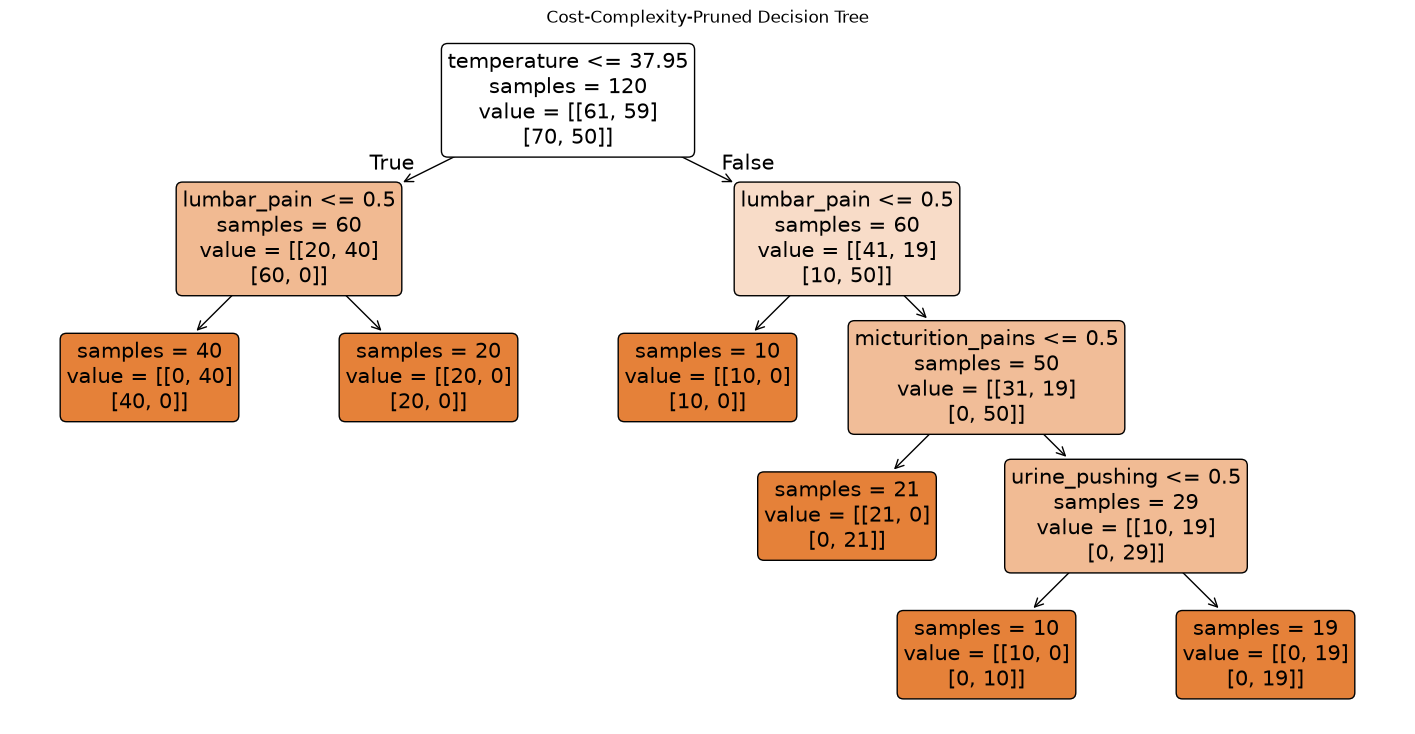

IF temperature <= 37.950 AND lumbar_pain <= 0.500
THEN bladder_inflammation = 1 AND nephritis = 0

IF temperature <= 37.950 AND lumbar_pain > 0.500
THEN bladder_inflammation = 0 AND nephritis = 0

IF temperature > 37.950 AND lumbar_pain <= 0.500
THEN bladder_inflammation = 0 AND nephritis = 0

IF temperature > 37.950 AND lumbar_pain > 0.500 AND micturition_pains <= 0.500
THEN bladder_inflammation = 0 AND nephritis = 1

IF temperature > 37.950 AND lumbar_pain > 0.500 AND micturition_pains > 0.500 AND urine_pushing <= 0.500
THEN bladder_inflammation = 0 AND nephritis = 1

IF temperature > 37.950 AND lumbar_pain > 0.500 AND micturition_pains > 0.500 AND urine_pushing > 0.500
THEN bladder_inflammation = 1 AND nephritis = 1



In [5]:
path = tree_full.cost_complexity_pruning_path(X_acute, y_acute)
alphas = np.unique(path.ccp_alphas[:-1])  # 去掉把树剪成根节点的最大 alpha

pruning_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid={"ccp_alpha": alphas},
    cv=5,
    scoring="accuracy"
)
pruning_search.fit(X_acute, y_acute)

tree_pruned = pruning_search.best_estimator_
print("Best ccp_alpha:", pruning_search.best_params_["ccp_alpha"])
print("CV accuracy:", pruning_search.best_score_)

plt.figure(figsize=(18, 9))
plot_tree(
    tree_pruned,
    feature_names=X_acute.columns,
    filled=True,
    rounded=True,
    impurity=False
)
plt.title("Cost-Complexity-Pruned Decision Tree")
plt.show()

print_if_then_rules(tree_pruned, X_acute.columns)

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
attribute_names = re.findall(
    r"^@attribute\s+(\S+)",
    COMMUNITIES_NAMES_PATH.read_text(encoding="utf-8"),
    flags=re.MULTILINE
)

crime_raw = pd.read_csv(
    COMMUNITIES_PATH,
    header=None,
    names=attribute_names,
    na_values="?"
)

non_predictive = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"

crime = crime_raw.drop(columns=non_predictive)
X = crime.drop(columns=target)
y = crime[target]

X_train, X_test = X.iloc[:1495].copy(), X.iloc[1495:].copy()
y_train, y_test = y.iloc[:1495].copy(), y.iloc[1495:].copy()

print(X_train.shape, X_test.shape)

(1495, 122) (499, 122)


### (b) Missing values

In [7]:
imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_imp = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values after imputation:", X_train_imp.isna().sum().sum())

Missing values after imputation: 0


### (c) Plot a correlation matrix

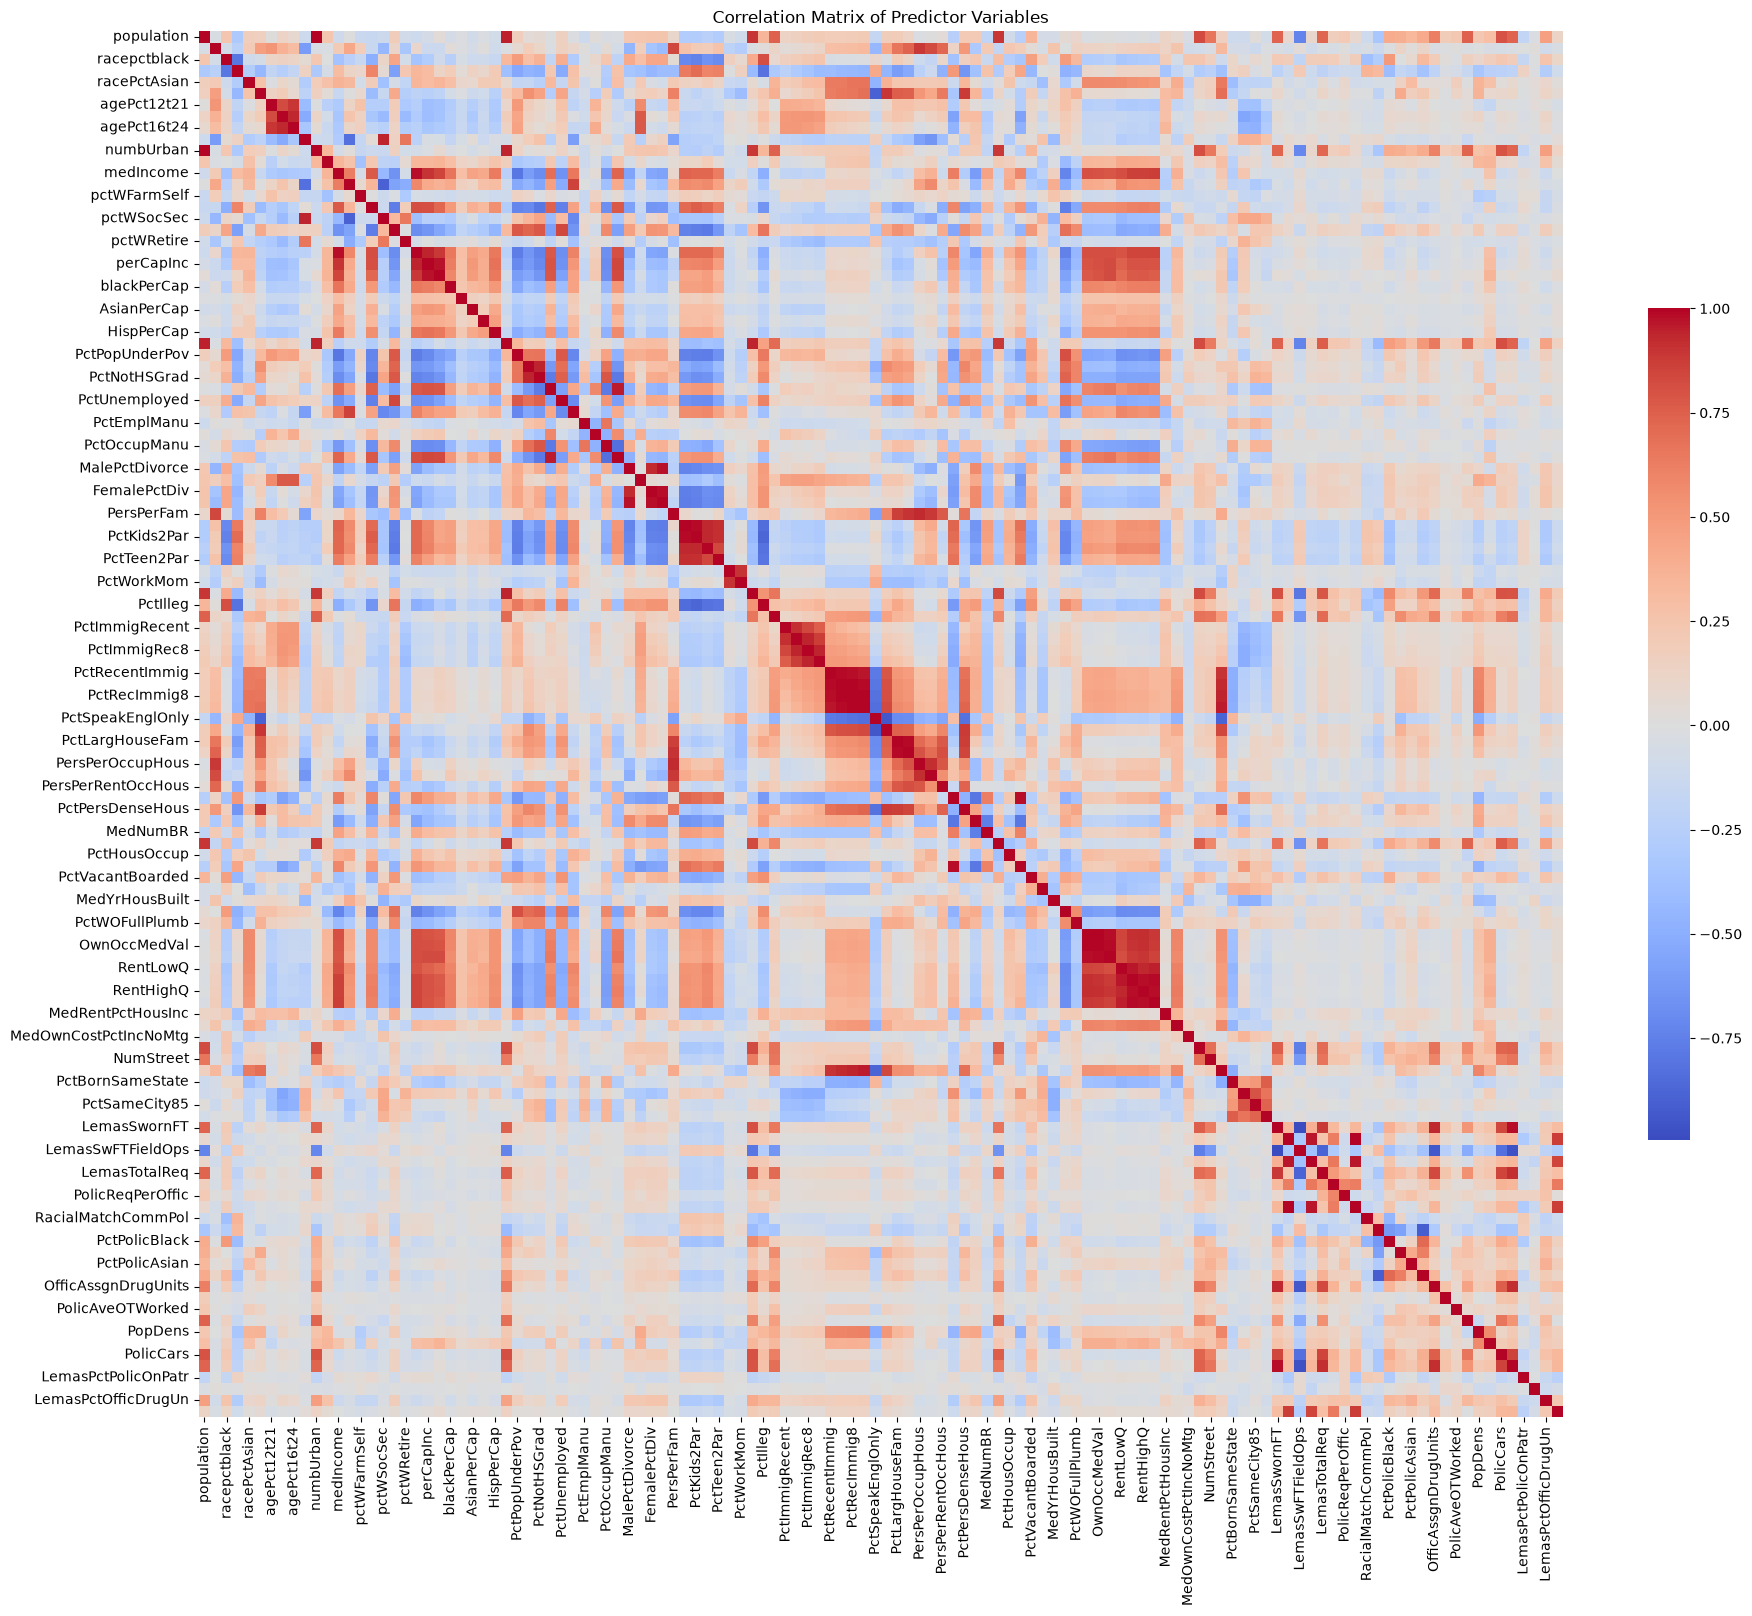

In [8]:
plt.figure(figsize=(22, 18))
sns.heatmap(X_train_imp.corr(), cmap="coolwarm", center=0, cbar_kws={"shrink": 0.6})
plt.title("Correlation Matrix of Predictor Variables")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
feature_cv = X_train_imp.std(ddof=1) / X_train_imp.mean().replace(0, np.nan)
feature_cv = feature_cv.sort_values(ascending=False)

top_features = feature_cv.head(int(np.ceil(np.sqrt(128)))).index.tolist()
display(feature_cv.head(12).to_frame("CV"))

,CV
PctPolicAsian,5.527059
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
LemasPctOfficDrugUn,2.552946
NumUnderPov,2.342443
LemasSwornFT,2.248042
population,2.241105
numbUrban,2.038461


### (e) Scatter plots and box plots for highest CV features

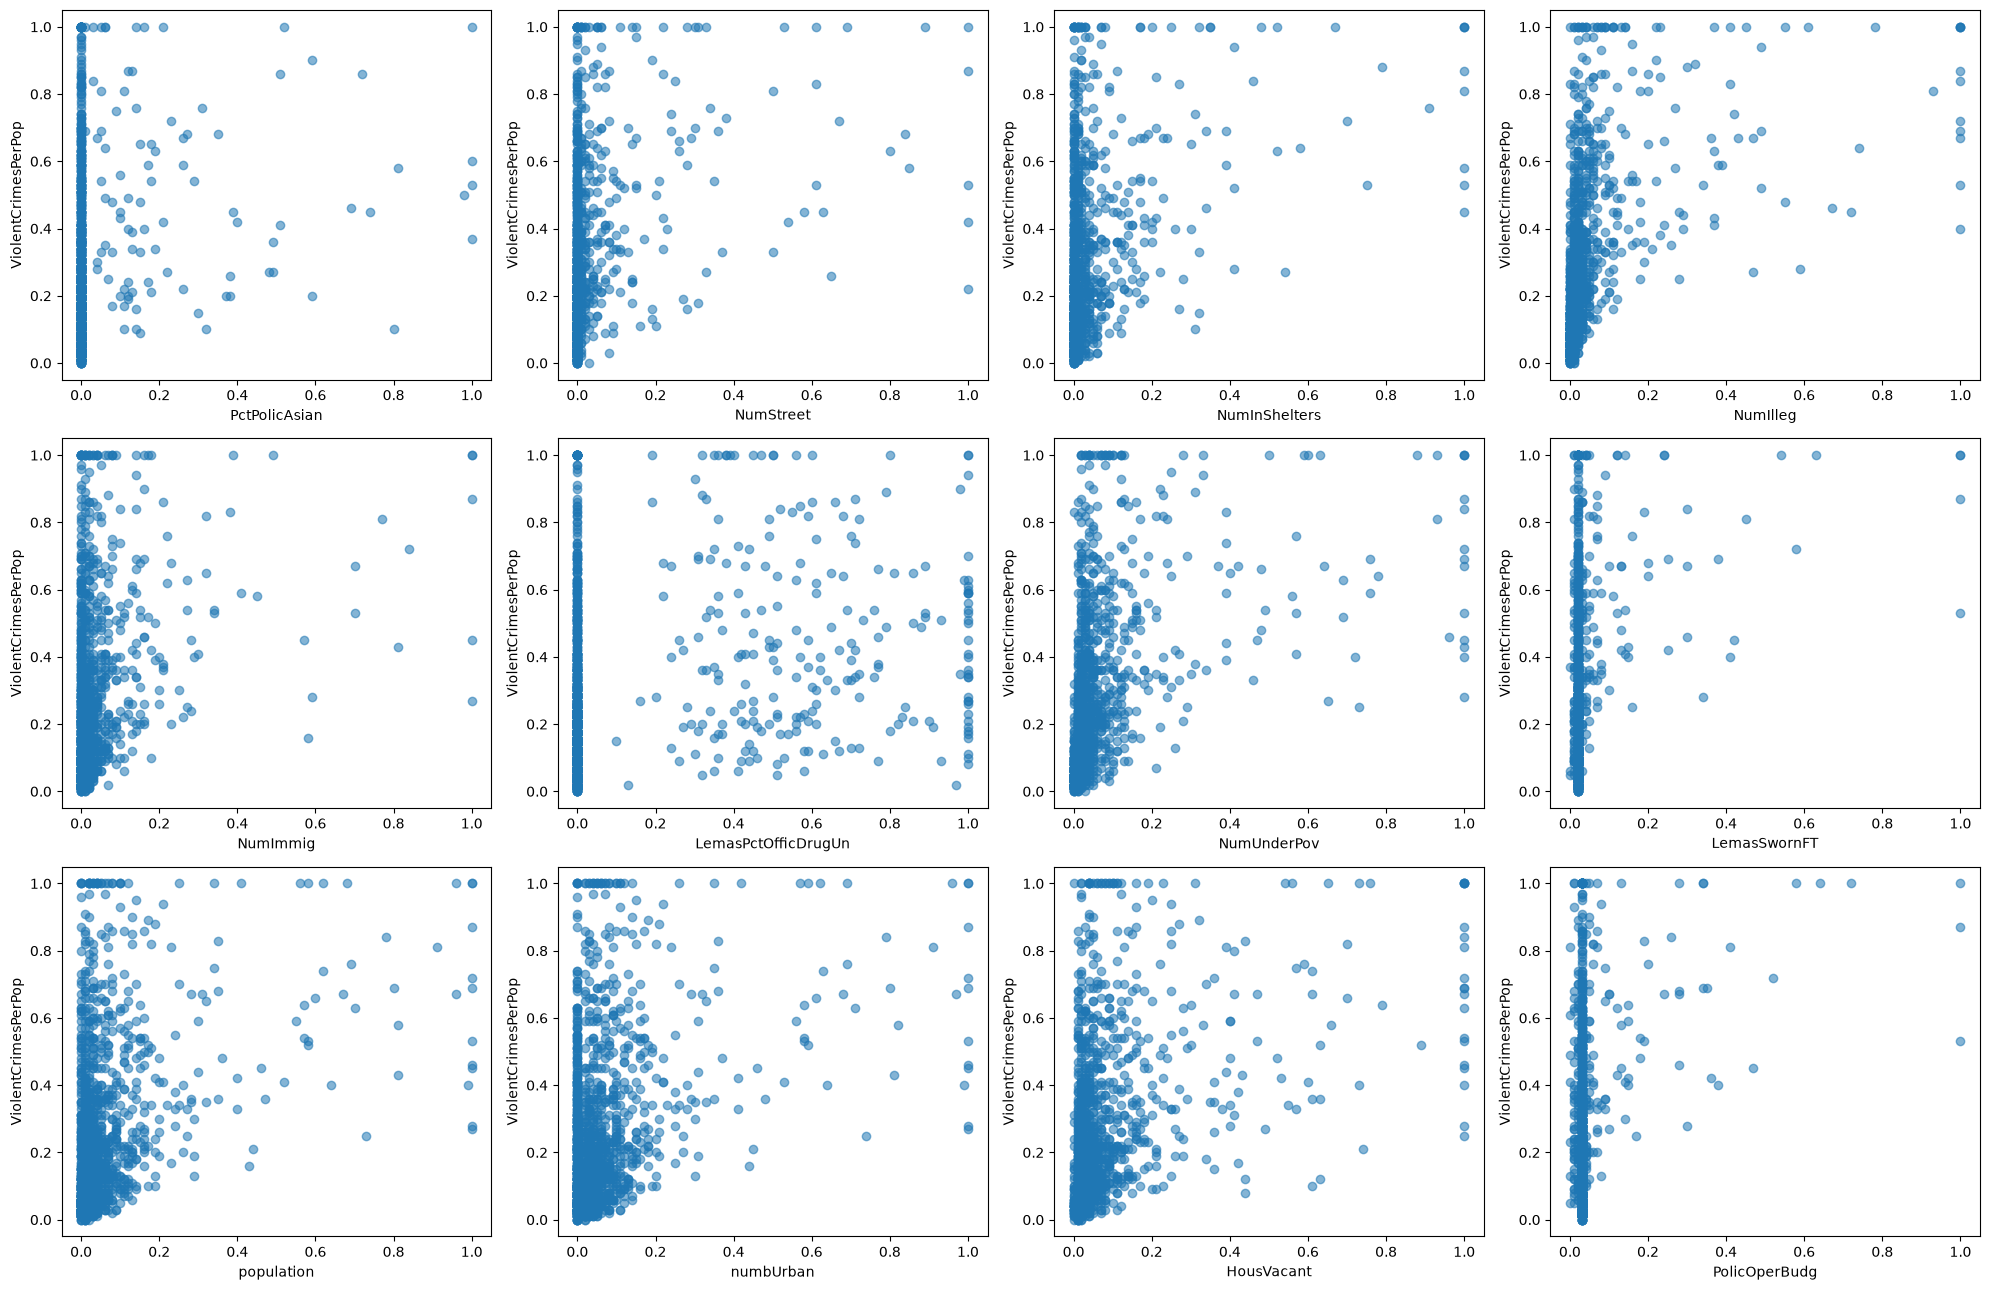

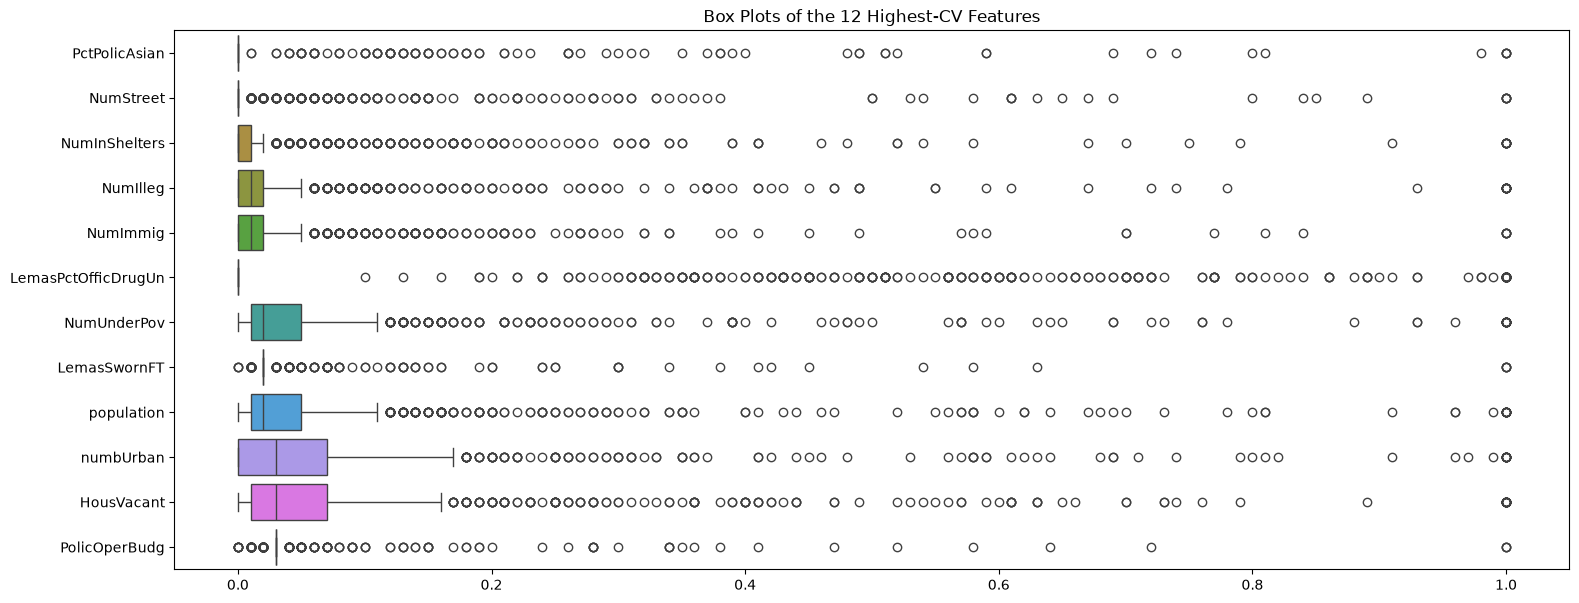

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(20, 13))
for ax, feature in zip(axes.ravel(), top_features):
    ax.scatter(X_train_imp[feature], y_train, alpha=0.55)
    ax.set_xlabel(feature)
    ax.set_ylabel(target)
plt.tight_layout()
plt.show()

plt.figure(figsize=(18, 7))
sns.boxplot(data=X_train_imp[top_features], orient="h")
plt.title("Box Plots of the 12 Highest-CV Features")
plt.show()

### (f) Fit a linear model

In [11]:
ols = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])
ols.fit(X_train, y_train)

ols_mse = mean_squared_error(y_test, ols.predict(X_test))
print(f"OLS test MSE: {ols_mse:.6f}")

OLS test MSE: 0.017966


### (g) Fit a ridge regression model

In [12]:
ridge = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RidgeCV(alphas=np.logspace(-4, 4, 100), cv=5))
])
ridge.fit(X_train, y_train)

ridge_mse = mean_squared_error(y_test, ridge.predict(X_test))
print("Best lambda:", ridge.named_steps["model"].alpha_)
print(f"Ridge test MSE: {ridge_mse:.6f}")

Best lambda: 79.24828983539186
Ridge test MSE: 0.017431


### (h) Fit a LASSO model

In [13]:
lasso_raw = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=50000))
])
lasso_raw.fit(X_train, y_train)
lasso_raw_mse = mean_squared_error(y_test, lasso_raw.predict(X_test))

lasso_std = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=50000))
])
lasso_std.fit(X_train, y_train)
lasso_std_mse = mean_squared_error(y_test, lasso_std.predict(X_test))

selected = X_train.columns[
    np.abs(lasso_std.named_steps["model"].coef_) > 1e-8
].tolist()

print(f"Unstandardized LASSO test MSE: {lasso_raw_mse:.6f}")
print(f"Standardized LASSO test MSE: {lasso_std_mse:.6f}")
print("Selected variables:")
print(selected)

Unstandardized LASSO test MSE: 0.017618
Standardized LASSO test MSE: 0.017682
Selected variables:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctS

### (i) Fit a PCR model

In [14]:
pcr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("model", LinearRegression())
])

pcr_search = GridSearchCV(
    pcr,
    param_grid={"pca__n_components": range(1, X_train.shape[1] + 1)},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)
pcr_search.fit(X_train, y_train)

pcr_mse = mean_squared_error(y_test, pcr_search.predict(X_test))
print("Best M:", pcr_search.best_params_["pca__n_components"])
print(f"PCR test MSE: {pcr_mse:.6f}")

Best M: 95
PCR test MSE: 0.018296


### (j) Fit a boosting tree

In [15]:
xgb = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", xgb)
])

xgb_search = GridSearchCV(
    xgb_pipe,
    param_grid={"model__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)
xgb_search.fit(X_train, y_train)

xgb_mse = mean_squared_error(y_test, xgb_search.predict(X_test))
print("Best alpha:", xgb_search.best_params_["model__reg_alpha"])
print(f"XGBoost test MSE: {xgb_mse:.6f}")

Best alpha: 1
XGBoost test MSE: 0.016255
